# Additive boosting: `gamboost`

`gamboost` fits an additive model by component-wise boosting. This page is for
readers who need effects that are not linear, or a mixture of linear, smooth and
grouped effects, and who have read the [glmboost](glmboost.ipynb) page. It covers
fitting and stopping, diagnostics, variable importance, partial effects, the
choice of `df` for a smooth term and the `env` argument, and gives the R
equivalent.

`gamboost` mixes arbitrary base learners in one formula: linear terms, smooth
P-splines, monotone splines, trees, spatial and random effects. Each appears as
an additive component and competes for selection at every iteration.

Spell out the base learner (`bbs(x)` for a smooth term, `bols(x)` for a linear
term). A bare column name is a front-end default
(`bbs` under `gamboost`, `bols` under `glmboost`) and is mapped differently in
the Python, R and upstream `mboost` examples.

In [1]:
import numpy as np
import mboostrs as mb

rng = np.random.default_rng(3)
n = 500
x1 = rng.uniform(-3, 3, n)         # smooth, nonlinear
x2 = rng.normal(size=n)            # linear
g = rng.integers(0, 6, n)          # grouping factor -> random effect
f_true = np.sin(x1) + 0.8 * x2 + (g - 2.5) * 0.4
y = f_true + rng.normal(scale=0.4, size=n)
data = {"x1": x1, "x2": x2, "g": g.astype(float), "y": y}

## Model with linear and smooth terms

`cvrisk` (detailed in [](model_selection.ipynb)) picks the stopping iteration by
evaluating out-of-sample risk on resampled folds. Here a single call finds the
optimal `mstop`. The model `fit` is fitted for the full 400 iterations; `cvrisk` only
returns the iteration `m_opt` at which the cross-validated risk is smallest and
does not truncate `fit`. The selected value, 386, is within 5% of the search cap
of 400, and `cvrisk` warns that the search range was exhausted, so a longer path
may select a larger value:

In [2]:
fit = mb.gamboost(
    "y ~ bbs(x1, df=4) + bols(x2) + brandom(g, df=4)",
    data=data,
    family=mb.Gaussian(),
    control=mb.boost_control(mstop=400, nu=0.1),
)
m_opt = fit.cvrisk(type="kfold", B=5, seed=1).optimal_mstop
m_opt

/Users/fcela/src/public_github/mboostrs/python/mboostrs/gamboost.py:3082: UserWarning: optimal mstop 386 is within 5% of the search cap 400; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


386

## Risk and diagnostics

In-bag risk and a 2×2 diagnostic dashboard give a quick health check:

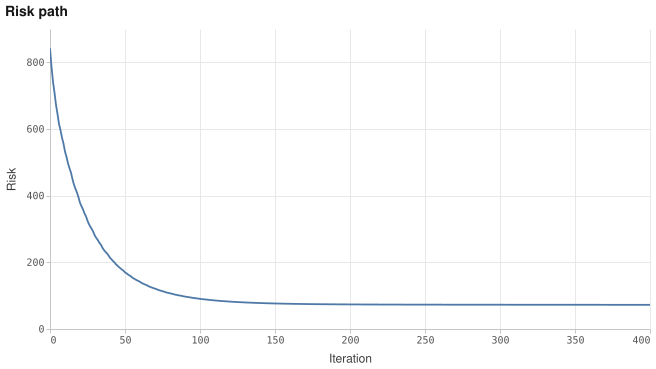

In [3]:
fit.plot_risk()

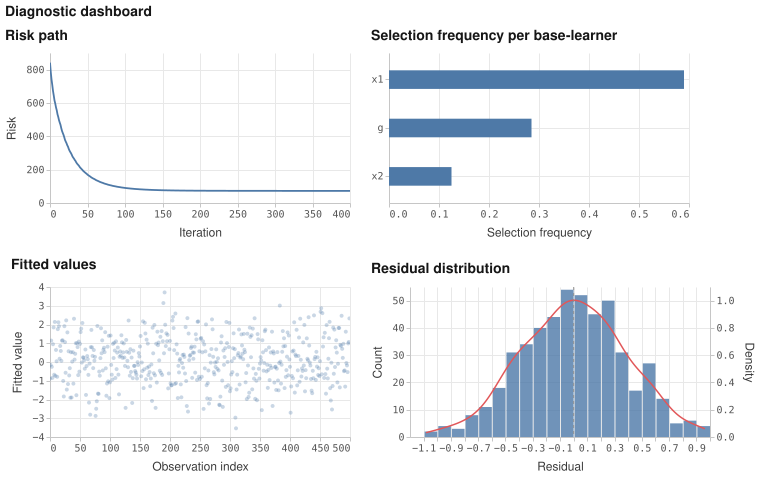

In [4]:
mb.plot.plot_diagnostics(fit)

`plot_diagnostics` shows risk path, selection frequencies, fitted vs. observed,
and residual distribution together.

## Variable importance: `varimp`

`varimp` summarizes the reduction in risk attributable to each base learner, a
boosting variable-importance measure. The result holds `reduction` (the risk
reduction credited to each learner) and `selfreq` (the fraction of iterations
in which the learner was selected).

In [5]:
fit.varimp()

{'reduction': {'x1': 0.3075162846974034,
  'x2': 0.38787436340989945,
  'g': 0.30460935189269717},
 'selfreq': {'x1': 0.59, 'x2': 0.125, 'g': 0.285},
 'variable_names': {'x1': 'x1', 'x2': 'x2', 'g': 'g'}}

## Visualizing the additive components

The built-in `plot_partial_effects` draws each learner's contribution
automatically:

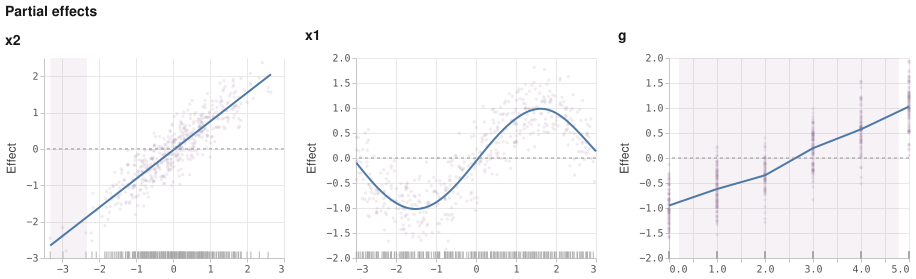

In [6]:
fit.plot_partial_effects()

You can also access the raw data with `fit.partial_effects()` and plot
manually for full control:

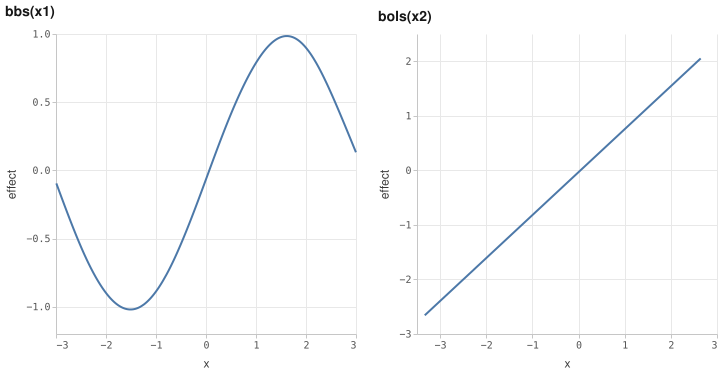

In [7]:
eff = fit.partial_effects()          # name -> (x_values, effect_values)
x1v, y1v = eff["x1"]; o1 = np.argsort(x1v)
x2v, y2v = eff["x2"]; o2 = np.argsort(x2v)
import polars as pl
import altair as alt
pd1 = pl.DataFrame({"x": x1v[o1], "effect": y1v[o1]})
pd2 = pl.DataFrame({"x": x2v[o2], "effect": y2v[o2]})
c1 = alt.Chart(pd1).mark_line().encode(x="x", y="effect").properties(title="bbs(x1)")
c2 = alt.Chart(pd2).mark_line().encode(x="x", y="effect").properties(title="bols(x2)")
alt.hconcat(c1, c2)

## Choosing `df`: under- and over-smoothing

`df` sets how flexible a smooth term is allowed to be (see
[](../methodology/penalties_df) for the df-to-$\lambda$ mapping). Too low and
the fit cannot bend enough to track the true curve; too high and it starts
tracking noise. Refit `bbs(x1, df=...)` alone (the true function is
$\sin(x_1)$) at three values of `df` and compare the recovered curve to the
truth:

In [8]:
df_rows = []
for df_val in [2, 4, 15]:
    df_fit = mb.gamboost(f"y ~ bbs(x1, df={df_val})", data={"x1": x1, "y": y},
                          family=mb.Gaussian(),
                          control=mb.boost_control(mstop=200, nu=0.1))
    xv, yv = df_fit.partial_effects()["x1"]
    o = np.argsort(xv)
    rmse = float(np.sqrt(np.mean((yv[o] - np.sin(xv[o])) ** 2)))
    print(f"df={df_val:2d}   RMSE to true sin(x1) = {rmse:.4f}")
    for xi, yi in zip(xv[o], yv[o]):
        df_rows.append({"x1": xi, "effect": yi, "df": f"df={df_val}"})


df= 2   RMSE to true sin(x1) = 0.4064
df= 4   RMSE to true sin(x1) = 0.0903
df=15   RMSE to true sin(x1) = 0.1625


/Users/fcela/src/public_github/mboostrs/python/mboostrs/formula.py:1224: UserWarning: df=2.0 equals the rank of the penalty's null space (the unpenalized part of the P-spline), which no finite lambda attains: the learner is fitted at maximum shrinkage and df= no longer sets its flexibility. Use df > 2, or center=True to remove the null space.
  learners.append(Bbs(name, **kwargs))


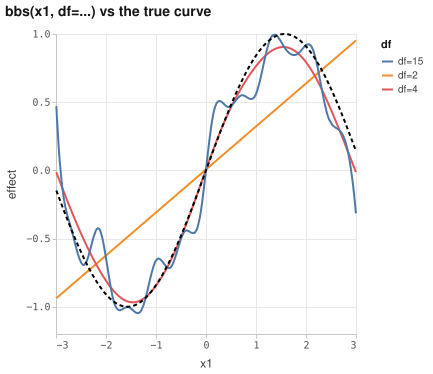

In [9]:
df_pdf = pl.DataFrame(df_rows)
truth_pdf = pl.DataFrame({"x1": np.sort(x1)}).with_columns(
    pl.col("x1").sin().alias("effect"),
    pl.lit("true sin(x1)").alias("df"),
)
fit_lines = alt.Chart(df_pdf).mark_line().encode(x="x1", y="effect", color="df:N")
truth_line = alt.Chart(truth_pdf).mark_line(strokeDash=[4, 3], color="black").encode(
    x="x1", y="effect"
)
(fit_lines + truth_line).properties(title="bbs(x1, df=...) vs the true curve")


`df=2` is too rigid to follow the sine curve's bends (visibly flatter than the
truth); `df=4` tracks it closely; `df=15` is flexible enough to start
wiggling with the noise between data points. In practice, pick `df` low
(4–6) and let `mstop` do most of the regularizing. Holding `df` low keeps
the comparison across base learners fair (see
[](../methodology/penalties_df)).

The warning printed by the `df=2` fit says that `df=2` equals the dimension of
the unpenalized part of the P-spline (a straight line), which no finite
smoothing parameter reaches. The term is therefore fitted at maximum shrinkage:
`df` no longer sets its flexibility, and the term can represent only a linear
effect. This explains the large RMSE (0.4064) for `df=2`. Use `df > 2`, or
`center=True`, to avoid it.

## The `env` parameter for matrix-backed learners

Learners that accept external matrices (`buser`, `bmrf`, `bconstrained`) need
those matrices passed separately rather than inlined in the formula string.
Use the `env` parameter to supply them by name:


In [10]:
X_custom = rng.normal(size=(n, 3))  # custom basis
K_custom = np.eye(3)                 # ridge penalty
beta = np.array([1.0, -0.5, 0.3])
y_custom = X_custom @ beta + rng.normal(scale=0.1, size=n)
data_custom = {"y": y_custom}

fit = mb.gamboost(
    "y ~ buser(custom, X=X_basis, K=K_penalty, df=4)",
    data=data_custom,
    family=mb.Gaussian(),
    control=mb.boost_control(200, 0.1),
    env={"X_basis": X_custom, "K_penalty": K_custom},
)
print(f"RMSE: {np.sqrt(np.mean((fit.fitted() - y_custom)**2)):.6f}")


RMSE: 0.106218


The `env` dict maps formula-time symbol names (`X_basis`, `K_penalty`)
to their numpy array values. The same pattern applies to `bmrf(..., K=...)`
and `bconstrained(..., C=...)`.


`fit.plot()` is a shortcut for `fit.plot_partial_effects()`. See
[](plotting_serialization.ipynb) for all plot functions.

## The same workflow in R

```r
library(mboostrs)
set.seed(3)
n <- 500
x1 <- runif(n, -3, 3)
x2 <- rnorm(n)
g <- floor(runif(n, 0, 6))
f_true <- sin(x1) + 0.8 * x2 + (g - 2.5) * 0.4
y <- f_true + rnorm(n, sd = 0.4)
data <- data.frame(x1 = x1, x2 = x2, g = g, y = y)

fit <- gamboost(y ~ bbs(x1, df = 4) + bols(x2) + brandom(g, df = 4),
                data = data,
                family = Gaussian(),
                control = boost_control(mstop = 400, nu = 0.1))

yhat <- predict(fit, newdata = data, type = "response")
cat("RMSE:", sqrt(mean((yhat - y)^2)), "\n")
```

## `gamboost` vs `glmboost`

`glmboost` is exactly `gamboost` restricted to `bols` learners. Use `glmboost`
for purely linear, high-dimensional models (its data path is specialized and
faster); use `gamboost` when you need smooth or structured effects.

## See also

- [](../methodology/base_learners) — the mathematical structure of each
  learner type (Bols, Bbs, Bmono, Bspatial, Brandom, Bmrf, Btree, Buser).
- [](../methodology/penalties_df) — how the `df` argument translates to a
  smoothing parameter and why df is the right currency for boosting.
- [](../methodology/functional_gradient_boosting) — the core algorithm:
  offset, gradient, base-learner selection, and update.
- [](../implementation/architecture) — the `Family` trait, the
  `PreparedLearner` contract, and how the engine loop ties them together.

The next page to read is [Base learners](base_learners.ipynb), which documents
every base learner.